In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, sampler
from torchvision import transforms
import torchvision.datasets as datasets

In [2]:
#print our pytorch version
print("Pytorch version: ", torch.__version__)
#check if we have cuda 
print("CUDA available:", torch.cuda.is_available())
print("Metal available:", torch.mps.is_available())

Pytorch version:  2.9.0
CUDA available: False
Metal available: True


In [3]:
#define a list of transforms because we might use more later, can also resize
transform = transforms.Compose([transforms.ToTensor()])

#convet the data into tensors using transform arg

#define two sets, a training set and validation (test) set
train_ds = datasets.MNIST(root = 'data', train = True, transform = transform , download = True)
test_ds = datasets.MNIST(root = 'data', train = False, transform = transform , download = True)


print(train_ds, test_ds)

100.0%
100.0%
100.0%
100.0%

Dataset MNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           ) Dataset MNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
           )


In [4]:
#split the dataset into 80% training and 20% test (validation) set
train_num = len(train_ds)

#make a list of the indicies
indicies = list(range(len(train_ds)))
#shuffle the indicies
np.random.shuffle(indicies)

#split the inidicies into 20 percent use floor to get rid of decimals and make into whole int
split = int(np.floor(0.2 * train_num))

#retrieve the data
val_indx, train_indx = indicies[:split], indicies[split:]


In [5]:
#dataloader uses sampler to pass in because we want to shuffle from the train indexes and test indexes by themselves

#sampler randomly samples from a list of given indexes
train_sampler = sampler.SubsetRandomSampler(train_indx)
val_sampler = sampler.SubsetRandomSampler(val_indx)


#create the train, test, validation dataloaders
train_dataloader = DataLoader(train_ds, batch_size = 32, sampler = train_sampler)

#for updating hyperparameters
val_dataloader = DataLoader(train_ds, batch_size = 32, sampler = val_sampler)

#don't shuffle test_dataloader because order doesn't matter
test_dataloader = DataLoader(test_ds, batch_size = 32)

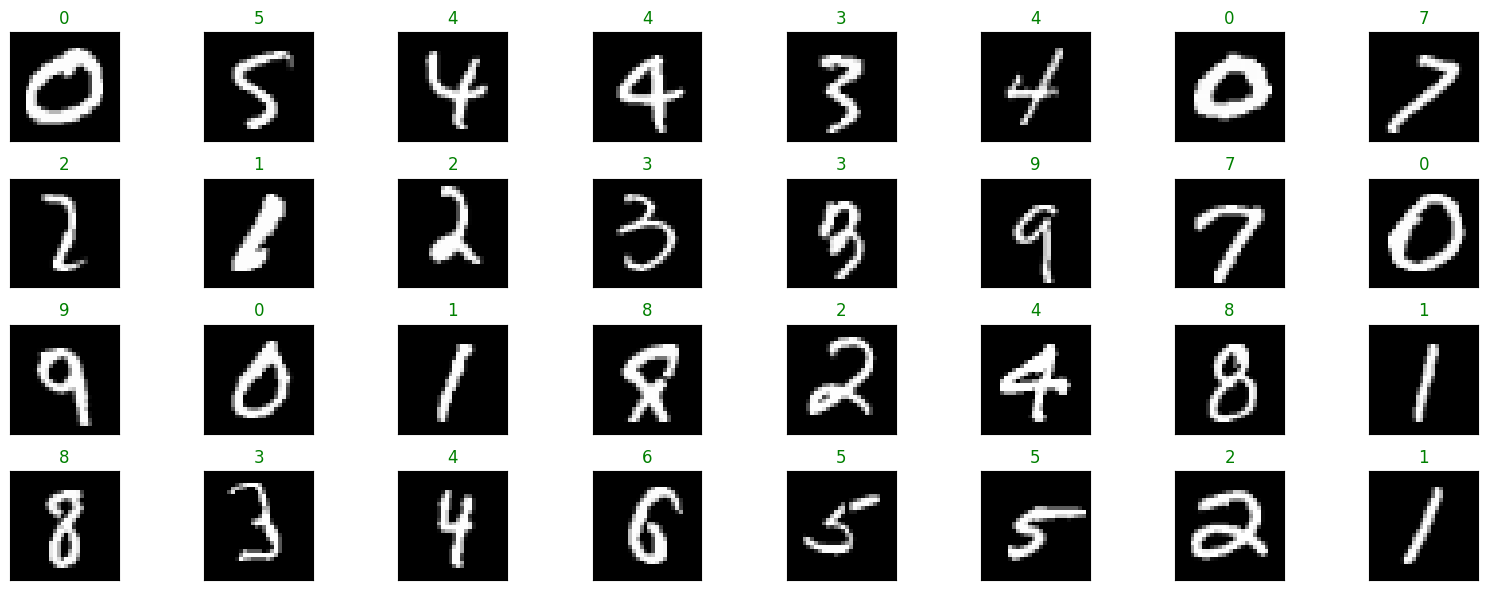

In [6]:
#plot the numbers we have

#get one sample of the data
one_sample = next(iter(train_dataloader))
#to get a single image to chart, use plt.figure
figure = plt.figure(figsize=(16, 6))

#getting the first batch of 32 images as above
for i in range(32):
    ax = figure.add_subplot(4, 8, i + 1, xticks = [], yticks = []) #get rid of ticks in images
    #extract the image and label (convert tensors into numpy so matplotlib can read)
    image, label = one_sample[0][i].numpy().squeeze(), one_sample[1][i].numpy().squeeze()
    #plot the image so matplotlib can read it
    ax.imshow(image, cmap = 'gray')

    #the number of the label for that image
    ax.set_title(label, fontsize = 12, color = 'green')

#formatting 
plt.tight_layout()
plt.show()


In [7]:
#declaring the actual neural network architecture
class Network(nn.Module):
    def __init__(self):
        #call the nn.module parent class
        super().__init__()
        #[120, 1, 28, 28] 28 * 28 * 1 = 784
        self.hidden0 = nn.Linear(784, 128)
        self.hidden1 = nn.Linear(128, 64)
        #we want 10 output features 0 - 9
        self.output = nn.Linear(64, 10)
        #using logsoftmax bc of nnnloss function
        self.softmax = nn.LogSoftmax(dim = 1)
        self.activation = nn.ReLU()
        #using dropout to avoid overfitting
        self.dropout = nn.Dropout(p = 0.30)


    #forward propagation run x through all layers
    def forward(self, x):
        #flatten first so dimentions match 784, then whatever the y dimention is
        x = x.view(x.shape[0], -1)
        #pass 1
        x = self.hidden0(x)
        x = self.activation(x)
        x = self.dropout(x)

        #pass 2
        x = self.hidden1(x)
        x = self.activation(x)
        x = self.dropout(x)

        x = self.output(x)
        #apply softmax before returning bc we want probabilities for multi classification
        x = self.softmax(x)

        return x
    
#initialize the network
model = Network()
print(model)


device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
print('using', device, 'for training')

Network(
  (hidden0): Linear(in_features=784, out_features=128, bias=True)
  (hidden1): Linear(in_features=128, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=10, bias=True)
  (softmax): LogSoftmax(dim=1)
  (activation): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
)
using cpu for training


In [8]:
#declare loss and optimizer functions
loss_func = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.01)

#check if cuda exists and what device is being used
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#change the model if cuda is available
model.to(device)
print('using', device, 'for training')


using cpu for training


In [9]:
#declare epoches
n_epoches = 10
#keep track of the losses
val_loss = []
#keep track of the losses
train_loss = []
min_val_loss = np.inf

#start training (training and validation loops)
for epoch in range(1, n_epoches + 1):
    #keep track of the losses for each epoch
    epoch_val_loss = 0
    epoch_train_loss = 0

    #TRAINING LOOP

    #set model to train mode
    model.train()
    #for each batch
    for image, label in train_dataloader:

        #move the label and image to the same device as model if available
        image, label = image.to(device), label.to(device) 
        #calculate the prediciton
        output = model(image)
        #loss function
        loss = loss_func(output, label)
        #zero the grad before updating grads
        optimizer.zero_grad()
        #update grad
        loss.backward()
        #update the grads from backprop
        optimizer.step()
        #add loss (the value, not the actual tensor itself)
        epoch_train_loss += loss.item()


    #VALIDATION LOOP

    #set the model to eval mode
    model.eval()
    #get rid of gradients
    with torch.no_grad():
        for image, label in val_dataloader:
            #set it again
            image, label = image.to(device), label.to(device)
            output = model(image)
            
            #loss function used to compare
            loss = loss_func(output, label)
            
            #add to the epoch_val_loss
            epoch_val_loss += loss.item()


    #calculate total loss per epoch (still still happens inside of the training loop)
    epoch_val_loss = epoch_val_loss / len(val_dataloader)
    epoch_train_loss = epoch_train_loss / len(train_dataloader)
    #append it to history so we can keep track of it
    val_loss.append(epoch_val_loss)
    train_loss.append(epoch_train_loss)

    #keep track of the training and validation stats
    print(f'Epoch: {epoch}/{n_epoches}: train_loss = {epoch_train_loss:.8f} val_loss = {epoch_val_loss:.8f}')
    #check if the val loss is less than the min loss, if yes save the model we have now currently
    if epoch_val_loss < min_val_loss:
        print(f'val_loss_decreased ({min_val_loss:.8f}) --> ({epoch_val_loss:.8f}), saving this model instead')
        #save the model we have
        torch.save(model.state_dict(), 'MNIST_model.pth')
        #set this epoch as the new min
        min_val_loss = epoch_val_loss

Epoch: 1/10: train_loss = 0.49177650 val_loss = 0.25834690
val_loss_decreased (inf) --> (0.25834690), saving this model instead
Epoch: 2/10: train_loss = 0.39413455 val_loss = 0.27540519
Epoch: 3/10: train_loss = 0.37269624 val_loss = 0.23773807
val_loss_decreased (0.25834690) --> (0.23773807), saving this model instead
Epoch: 4/10: train_loss = 0.36628042 val_loss = 0.24414127
Epoch: 5/10: train_loss = 0.34769483 val_loss = 0.23080527
val_loss_decreased (0.23773807) --> (0.23080527), saving this model instead
Epoch: 6/10: train_loss = 0.35318532 val_loss = 0.23433386
Epoch: 7/10: train_loss = 0.34722434 val_loss = 0.26833260
Epoch: 8/10: train_loss = 0.33917867 val_loss = 0.21803979
val_loss_decreased (0.23080527) --> (0.21803979), saving this model instead
Epoch: 9/10: train_loss = 0.32852842 val_loss = 0.23737442
Epoch: 10/10: train_loss = 0.32151336 val_loss = 0.24617562


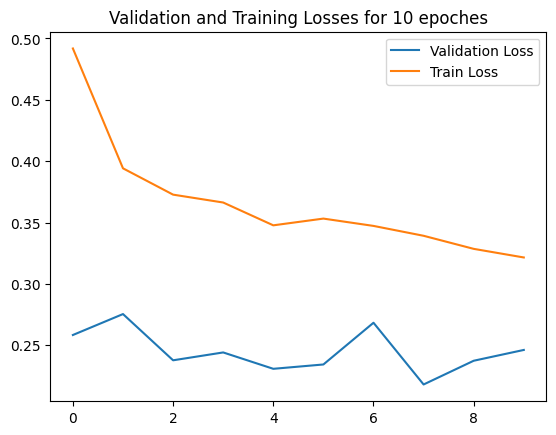

In [10]:
#plot the val losses and train loss
plt.title("Validation and Training Losses for 10 epoches")
plt.plot(val_loss, label = "Validation Loss")
plt.plot(train_loss, label = "Train Loss")
plt.legend()
plt.show()


In [11]:
#defining model and stuff for test phase
model = Network()
#load our weights from the trained model
model.load_state_dict(torch.load("MNIST_model.pth"))

loss_fn = nn.NLLLoss()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
print('using', device, 'for testing')


using cpu for testing


In [13]:
#testing our model on test data
model.eval()
test_loss = 0.0
test_acc = 0.0

#dictionary to keep track of correctness from model
correct_count = {i:0 for i in range(10)}
total_count = {i:0 for i in range(10)}

#store predictions and actual labels for visualization
#we'll just grab one batch for visualization - simpler!
sample_images = None
sample_labels = None
sample_predictions = None

with torch.no_grad():
    for images, labels in test_dataloader:
        #move to gpu if exists
        images, labels = images.to(device), labels.to(device)
        #make prediction
        outputs = model(images)
        #since using log softmax, convert each output to exp
        pred_label_proba = torch.exp(outputs)
        
        loss = loss_fn(outputs, labels)
        #compute test loss
        test_loss += loss.item()
        
        #get predicted labels (indices of max values)
        #torch.max returns (max_values, indices) - we only want indices, so use _
        _, pred_labels = torch.max(pred_label_proba, dim=1)
        
        #calculate accuracy for this batch
        correct = (pred_labels == labels).sum().item()
        test_acc += correct
        
        #save first batch for visualization (much simpler!)
        if sample_images is None:
            sample_images = images.cpu()  #keep as tensor, convert to numpy later
            sample_labels = labels.cpu()
            sample_predictions = pred_labels.cpu()
        
        #update per-class statistics
        for i in range(len(labels)):
            label = labels[i].item()  #convert tensor to regular number
            total_count[label] += 1
            if pred_labels[i] == labels[i]:
                correct_count[label] += 1

#calculate average test loss and accuracy
test_loss = test_loss / len(test_dataloader)
test_acc = test_acc / len(test_dataloader.dataset)

print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')
print('\nPer-class accuracy:')
for i in range(10):
    if total_count[i] > 0:
        acc = correct_count[i] / total_count[i]
        print(f'Class {i}: {acc:.4f} ({acc*100:.2f}%) - {correct_count[i]}/{total_count[i]} correct')


Test Loss: 0.2329
Test Accuracy: 0.9470 (94.70%)

Per-class accuracy:
Class 0: 0.9765 (97.65%) - 957/980 correct
Class 1: 0.9753 (97.53%) - 1107/1135 correct
Class 2: 0.9409 (94.09%) - 971/1032 correct
Class 3: 0.9455 (94.55%) - 955/1010 correct
Class 4: 0.9542 (95.42%) - 937/982 correct
Class 5: 0.9170 (91.70%) - 818/892 correct
Class 6: 0.9656 (96.56%) - 925/958 correct
Class 7: 0.9582 (95.82%) - 985/1028 correct
Class 8: 0.9117 (91.17%) - 888/974 correct
Class 9: 0.9187 (91.87%) - 927/1009 correct


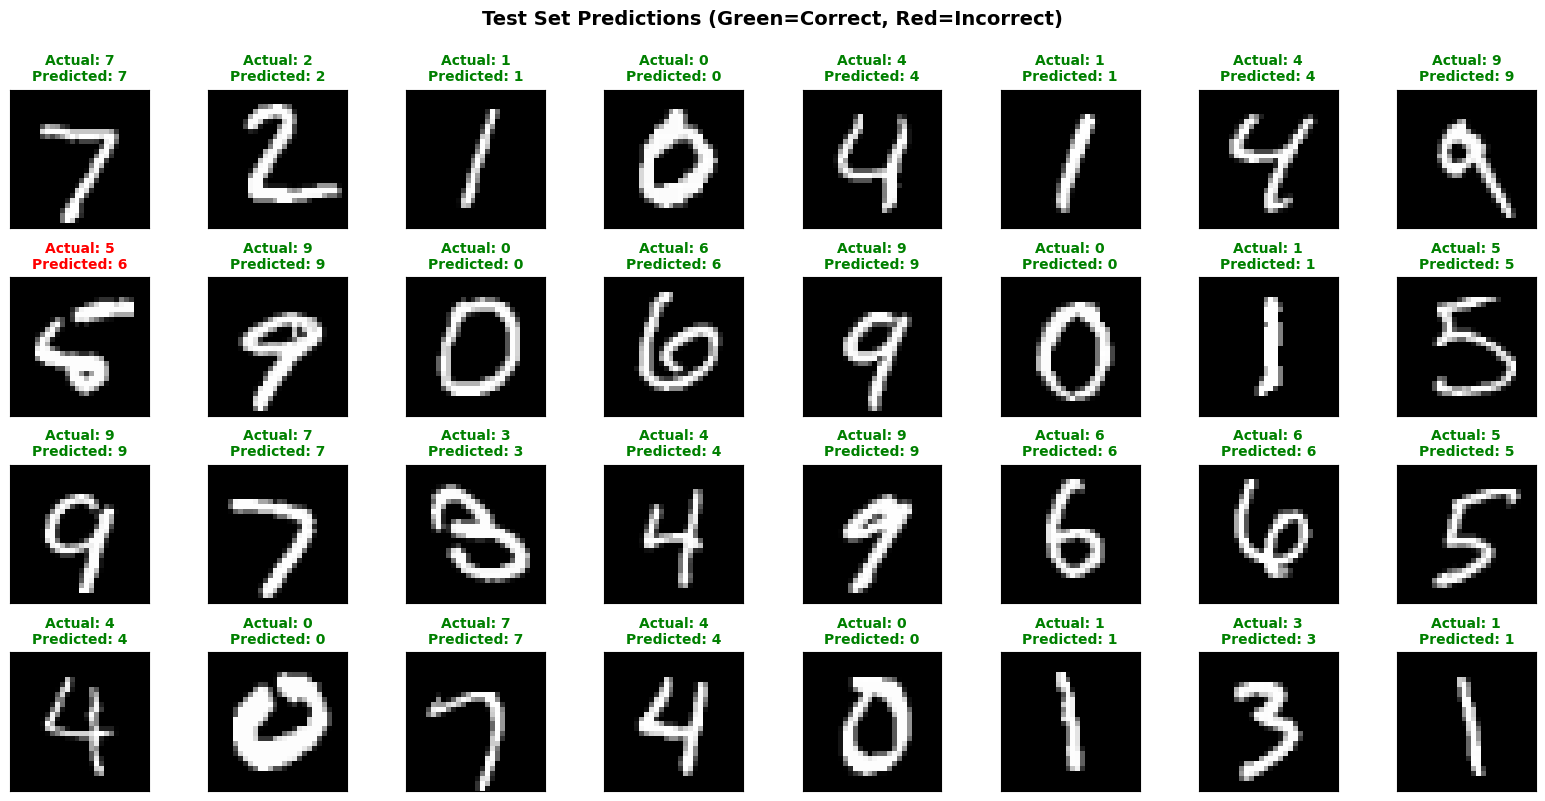

In [14]:
#visualize test predictions - much simpler now!
#we already saved one batch (32 images) from the test loop above

#convert tensors to numpy (matplotlib needs numpy, not tensors)
images_np = sample_images.numpy()  #shape: (32, 1, 28, 28)
labels_np = sample_labels.numpy()  #shape: (32,)
preds_np = sample_predictions.numpy()  #shape: (32,)

#create figure with 32 subplots (4 rows x 8 columns)
figure = plt.figure(figsize=(16, 8))

#loop through all 32 images in the batch
for i in range(32):
    ax = figure.add_subplot(4, 8, i + 1, xticks=[], yticks=[])
    
    #get image, actual label, and predicted label
    #squeeze() removes the channel dimension: (1, 28, 28) -> (28, 28)
    image = images_np[i].squeeze()
    actual_label = labels_np[i]
    predicted_label = preds_np[i]
    
    #display image
    ax.imshow(image, cmap='gray')
    
    #color code: green if correct, red if incorrect
    color = 'green' if actual_label == predicted_label else 'red'
    
    #set title with actual and predicted labels
    ax.set_title(f'Actual: {actual_label}\nPredicted: {predicted_label}', 
                 fontsize=10, color=color, fontweight='bold')

plt.suptitle('Test Set Predictions (Green=Correct, Red=Incorrect)', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
